In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuring display settings
plt.rcParams['figure.figsize'] = (12, 9)
sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings("ignore", category=FutureWarning)
import json

In [2]:
# Import config variable
with open("../../config.json") as f:
    cfg = json.load(f)
    
target = cfg["rc"]        
file_name = cfg["rc_file_name"]   
random_state = cfg["split"]["random_state"]  
# Load the dataset
data = pd.read_csv(f"../../data/{file_name}.csv")

In [3]:
from sklearn.model_selection import train_test_split
import numpy as np

X = data.drop(columns=[target])
y = data[target]

# Tirage de 4 seeds aléatoires différentes
master_rng = np.random.default_rng(seed=99)
seeds = master_rng.choice(10000, size=4, replace=False).tolist()
print("Seeds sélectionnées :", seeds)

# Split fixe utilisé par la grille de recherche ci-dessous
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Seeds sélectionnées : [5650, 7575, 5059, 9578]
Training set size: 307 samples
Test set size: 77 samples


{'max_depth': 6, 'max_features': 0.7, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
MAE (test): 2.036743699895664
RMSE (test): 2.6815368126881363
R² (test): 0.8986894509035118
 
MAE (train): 1.5200115396495575
RMSE (train): 2.16366264422001
R² (train): 0.9278014939833882


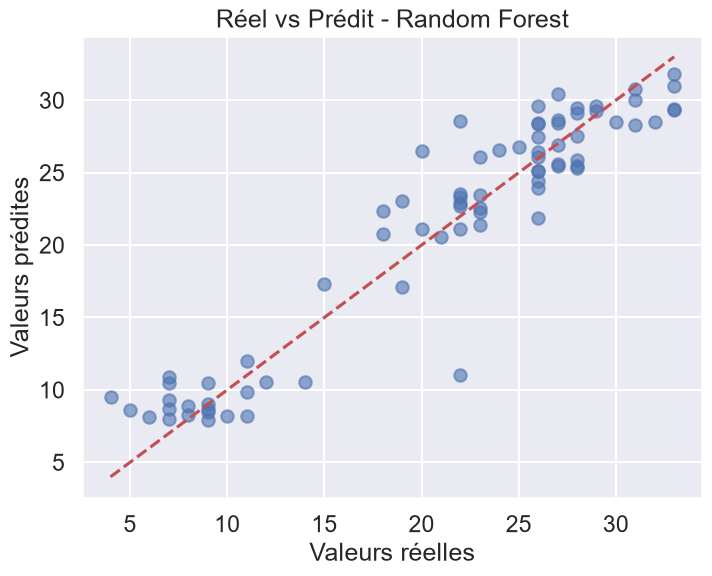

In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [None, 6, 8, 10],   # None = pas de limite
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10], # paramètre non testé actuellement
    'max_features': ['sqrt', 0.3, 0.5, 0.7],
}


grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)
print(grid_search.best_params_)

best_model = grid_search.best_estimator_
# Prédictions
y_pred = best_model.predict(X_test)

# Évaluation sur le test set
print("MAE (test):", mean_absolute_error(y_test, y_pred))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² (test):", r2_score(y_test, y_pred))
print(" ")

# Évaluation sur le train set
print("MAE (train):", mean_absolute_error(y_train, best_model.predict(X_train)))
print("RMSE (train):", np.sqrt(mean_squared_error(y_train, best_model.predict(X_train))))
print("R² (train):", r2_score(y_train, best_model.predict(X_train)))

# Visualisation réel vs prédit
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - Random Forest')
plt.show()

In [ ]:
import joblib
joblib.dump(best_model, 'saved_models/random_forest_rc.pkl')

['saved_models/random_forest_rc.pkl']

In [4]:
import joblib
import os
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs('saved_models', exist_ok=True)

# Tirage de 4 seeds aléatoires différentes
master_rng = np.random.default_rng(seed=99)
seeds = master_rng.choice(10000, size=4, replace=False).tolist()
print("Seeds sélectionnées :", seeds)

param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [None, 6, 8, 10],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 0.3, 0.5, 0.7],
}

results_per_seed = {}

for seed in seeds:
    print(f"\n{'='*50}")
    print(f"Entraînement Random Forest avec seed = {seed}")
    print(f"{'='*50}")

    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )

    gs = GridSearchCV(
        RandomForestRegressor(random_state=seed),
        param_grid,
        cv=5,
        scoring='r2',
        n_jobs=-1,
        verbose=0
    )
    gs.fit(X_train_s, y_train_s)
    print(f"Meilleurs params : {gs.best_params_}")

    model_s = gs.best_estimator_

    y_pred_s = model_s.predict(X_test_s)
    r2_test  = r2_score(y_test_s, y_pred_s)
    mae_test = mean_absolute_error(y_test_s, y_pred_s)
    mse_test = mean_squared_error(y_test_s, y_pred_s)
    r2_train = r2_score(y_train_s, model_s.predict(X_train_s))

    print(f"R² train : {r2_train:.4f}")
    print(f"R² test  : {r2_test:.4f}")
    print(f"MAE test : {mae_test:.4f}")
    print(f"RMSE test: {np.sqrt(mse_test):.4f}")

    results_per_seed[seed] = {
        "r2_train":    r2_train,
        "r2_test":     r2_test,
        "mae_test":    mae_test,
        "rmse_test":   np.sqrt(mse_test),
        "best_params": gs.best_params_,
    }

    joblib.dump(model_s, f'saved_models/random_forest_seed_{seed}.pkl')
    print(f"  -> saved_models/random_forest_seed_{seed}.pkl")

print("\n\n=== Récapitulatif ===")
for s, m in results_per_seed.items():
    print(f"seed={s:5d}  R²_train={m['r2_train']:.4f}  R²_test={m['r2_test']:.4f}  MAE={m['mae_test']:.4f}  RMSE={m['rmse_test']:.4f}")

Seeds sélectionnées : [5650, 7575, 5059, 9578]

Entraînement Random Forest avec seed = 5650
Meilleurs params : {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
R² train : 0.9432
R² test  : 0.9105
MAE test : 1.8532
RMSE test: 2.4285
  -> saved_models/random_forest_seed_5650.pkl

Entraînement Random Forest avec seed = 7575
Meilleurs params : {'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
R² train : 0.9664
R² test  : 0.7716
MAE test : 2.2320
RMSE test: 3.7073
  -> saved_models/random_forest_seed_7575.pkl

Entraînement Random Forest avec seed = 5059
Meilleurs params : {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
R² train : 0.9784
R² test  : 0.8962
MAE test : 1.9414
RMSE test: 2.6788
  -> saved_models/random_forest_seed_5059.pkl

Entraînement Random Forest avec seed = 9578
Meilleurs params : {'max_depth': 8, 'm